In [1]:
%%time
dataset_name = "W30_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (12866, 13)
old_new_col_names not loaded
CPU times: total: 16.7 s
Wall time: 17.4 s


In [2]:
pan_dataset_values = pd.read_pickle(BES_small_data_files+"pan_dataset_allr_valuesW19.zip",compression='zip')
import panel as pn
from symfit import Poly, variables, parameters, Model, Fit


x, y, z = variables('x, y, z')
c1, c2, c3 = parameters('c1, c2, c3')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(1, 0): c1, (0, 1): c2, (0,0):c3 }, x ,y).as_expr()
}
model = Model(model_dict)
print(model)

mask = BES_Panel["likeConW24"].isnull() # stand in for any like<Party>W24 variables - maybe use weights instead?

BES_Panel["likeBrexitPartyW24"] = BES_Panel["likeBrexitPartyW23"]

BES_Panel.loc[mask,"likeBrexitPartyW24"]=np.nan
new_mask = (~mask)&BES_Panel["likeBrexitPartyW24"].isnull()

BES_Panel.loc[new_mask,"likeBrexitPartyW24"]=BES_Panel.loc[new_mask,"likeBrexitPartyW25"]
BES_Panel.loc[~mask,"likeBrexitPartyW24"].isnull().sum()


BES_Panel["likeGrnW24"] = BES_Panel["likeGrnW23"]

BES_Panel.loc[mask,"likeGrnW24"]=np.nan
new_mask = (~mask)&BES_Panel["likeGrnW24"].isnull()

BES_Panel.loc[new_mask,"likeGrnW24"]=BES_Panel.loc[new_mask,"likeGrnW25"]
BES_Panel.loc[~mask,"likeGrnW24"].isnull().sum()


# bit weak, bit shit, it's partial wave, mostly wave 23, some from wave 25


wave_to_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Date_Start"]
wave_to_date[26]="Apr-24"
wave_to_date[27]="May-24"
wave_to_date[28]="Jun-24"
wave_to_date[29]="Jul-24"
wave_to_date[30]="May-25"

wave_to_date = pd.to_datetime(wave_to_date,format="%b-%y")
wave_to_date

max_wave = 30

[z(x, y; c1, c2, c3) = c1*x + c2*y + c3]


In [3]:
# df_var = pd.read_pickle( "df_var.zip" , compression='zip' )

In [3]:
# search(BES_Panel,"al_scale")

wave_to_al_var = {1:"al_scaleW1_W5",2:"al_scaleW1_W5",3:"al_scaleW1_W5",4:"al_scaleW1_W5",5:"al_scaleW1_W5",
                    6:"al_scaleW6",7:"al_scaleW7_W9",8:"al_scaleW7_W9",9:"al_scaleW7_W9",
                    10:"al_scaleW10_W12",11:"al_scaleW10_W12",12:"al_scaleW10_W12",13:"al_scaleW13",
                    14:"al_scaleW14W15",15:"al_scaleW14W15",16:"al_scaleW16",
                    17:"al_scaleW17_W19",18:"al_scaleW17_W19",19:"al_scaleW17_W19",
                    20:"al_scaleW20",21:"al_scaleW21",22:"al_scaleW22",23:"al_scaleW23",24:"al_scaleW24",
                    25:"al_scaleW25W26",26:"al_scaleW25W26",27:"al_scaleW27W29",28:"al_scaleW27W29",29:"al_scaleW27W29",30:"al_scaleW30",
                    1987:"Social: Lib(0) <-> Auth(20)W1987",1992:"Social: Lib(0) <-> Auth(20)W1992",1997:"Social: Lib(0) <-> Auth(20)W1997",
                    2001:"Social: Lib(0) <-> Auth(20)W2001",2005:"Social: Lib(0) <-> Auth(20)W2005",2010:"Social: Lib(0) <-> Auth(20)W2010",
                    2015:"Social: Lib(0) <-> Auth(20)W2015",2017:"Social: Lib(0) <-> Auth(20)W2017",2019:"Social: Lib(0) <-> Auth(20)W2019",
                   }

wave_to_lr_var = {1:"lr_scaleW1_W5",2:"lr_scaleW1_W5",3:"lr_scaleW1_W5",4:"lr_scaleW1_W5",5:"lr_scaleW1_W5",
                    6:"lr_scaleW6",7:"lr_scaleW7_W9",8:"lr_scaleW7_W9",9:"lr_scaleW7_W9",
                    10:"lr_scaleW10_W12",11:"lr_scaleW10_W12",12:"lr_scaleW10_W12",13:"lr_scaleW13",
                    14:"lr_scaleW14W15",15:"lr_scaleW14W15",16:"lr_scaleW16",
                    17:"lr_scaleW17_W19",18:"lr_scaleW17_W19",19:"lr_scaleW17_W19",
                    20:"lr_scaleW20",21:"lr_scaleW21",22:"lr_scaleW22",23:"lr_scaleW23",24:"lr_scaleW24",
                    25:"lr_scaleW25W26",26:"lr_scaleW25W26",27:"lr_scaleW27W29",28:"lr_scaleW27W29",29:"lr_scaleW27W29",30:"lr_scaleW30",
                    1987:"Economic: Left(0) <-> Right(20)W1987",1992:"Economic: Left(0) <-> Right(20)W1992",1997:"Economic: Left(0) <-> Right(20)W1997",
                    2001:"Economic: Left(0) <-> Right(20)W2001",2005:"Economic: Left(0) <-> Right(20)W2005",2010:"Economic: Left(0) <-> Right(20)W2010",
                    2015:"Economic: Left(0) <-> Right(20)W2015",2017:"Economic: Left(0) <-> Right(20)W2017",2019:"Economic: Left(0) <-> Right(20)W2019",
                   }

Friendly_description = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Friendlier_Description"]
Friendly_description.loc[1987] = "BESf2f 1987 GE"
Friendly_description.loc[1992] = "BESf2f 1992 GE"
Friendly_description.loc[1997] = "BESf2f 1997 GE"
Friendly_description.loc[2001] = "BESf2f 2001 GE"
Friendly_description.loc[2005] = "BESf2f 2005 GE"
Friendly_description.loc[2010] = "BESf2f 2010 GE"
Friendly_description.loc[2015] = "BESf2f 2015 GE"
Friendly_description.loc[2017] = "BESf2f 2017 GE"
Friendly_description.loc[2019] = "BESf2f 2019 GE"
Friendly_description.loc[2024] = "BESf2f 2024 GE"

wave_to_date

wave_to_date.loc[1987] = pd.to_datetime("11-06-1987")
wave_to_date.loc[1992] = pd.to_datetime("9-04-1992")
wave_to_date.loc[1997] = pd.to_datetime("1-05-1997")
wave_to_date.loc[2001] = pd.to_datetime("7-06-2001")
wave_to_date.loc[2005] = pd.to_datetime("5-05-2005")
wave_to_date.loc[2010] = pd.to_datetime("6-05-2010")
wave_to_date.loc[2015] = pd.to_datetime("7-05-2015")
wave_to_date.loc[2017] = pd.to_datetime("8-06-2017")
wave_to_date.loc[2019] = pd.to_datetime("12-12-2019")
wave_to_date.loc[2024] = pd.to_datetime("4-6-2024")#4 July 2024

In [4]:
df_var = pd.read_pickle( "df_var_all.zip" , compression='zip' )
df = pd.read_pickle( "df_all.zip" , compression='zip' )

In [26]:
row_var

'VISDPW2019'

In [93]:
from matplotlib import cm
import holoviews as hv
hv.extension('matplotlib')
hmap = hv.HoloMap(kdims=['raw_or_modelled', 'like_or_ptv', 'party', 'wave'])


q=11
half_q = int((q-1)/2) ## make sure it *is* an int!

wave = 30
party = "Con"
like_or_ptv = "like"
raw_or_modelled = "raw"

# parties = ["Con","Lab","LD","BrexitParty","UKIP","SNP","PC","Grn","TIG","BNP","DUP","OTH","Ref","SDP"]
parties = ["Con","Lab","LD","Grn" ]
all_bes_waves = list(range(1,31))+[1987,1992,1997,2001,2005,2010,2015,2017,2019]

for raw_or_modelled in ["raw","modelled"]:
    for like_or_ptv in ["like","ptv"]:
                        #,"VI"]:
        for party in parties:
            for wave in all_bes_waves:
                        
                # (raw/modelled) x (wave) x (party) x (like|ptv|VI) crude 10 x 10 surfaces
                
                row_var = like_or_ptv+party+"W"+str(wave)
                if row_var not in df_var.index:                
                    continue
                else:
                    print(raw_or_modelled,row_var)
                
                y_lab = wave_to_lr_var[wave]
                x_lab = wave_to_al_var[wave]
                
                x_vec = np.linspace(-half_q, half_q,q)
                y_vec = np.linspace(-half_q, half_q,q)
                xdata, ydata = np.meshgrid(x_vec, y_vec)
                if raw_or_modelled == "raw":
                    zdata = pd.crosstab(pd.qcut(df[y_lab]+np.random.rand(df.shape[0])*.01,q=q).cat.codes.replace(-1,np.nan)-half_q,
                                        pd.qcut(df[x_lab]+np.random.rand(df.shape[0])*.01,q=q).cat.codes.replace(-1,np.nan)-half_q,
                                        values = df[row_var],aggfunc=np.mean).values
                elif raw_or_modelled == "modelled":
                
                    fit_result = df_var.loc[row_var,"fit_result"]
                    zdata = model(x=xdata/half_q, y=ydata/half_q, **fit_result.params).z
                
                if zdata.shape != (q,q):
                    continue
                
                # fig = plt.figure(figsize=(12, 8))
                # ax = fig.add_subplot(projection='3d')
                
                
                # Plot the surface.
                # surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                #                        linewidth=0, antialiased=False,)
                # surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                #                        linewidth=0, antialiased=False,)
                ylabel = "Economic: Left(-"+str(half_q)+") <-> Right("+str(half_q)+")"
                xlabel = "Social: Lib(-"+str(half_q)+") <-> Auth("+str(half_q)+")"
                # ax.set(ylabel=(ylabel),  xlabel=(xlabel), );
                title = like_or_ptv.capitalize()+" "+party+" "+raw_or_modelled + " (0-10)\n"+Friendly_description[wave]
                # ax.set_title(title, fontsize=18)
                # ax.set_box_aspect(aspect=None, zoom=0.8)
                # plt.xlim((-half_q, half_q));
                # plt.ylim((-half_q, half_q));
                # ax.set_zlim((0, 10));

                fs_dict = {'title':16,'labels':12,'ticks':10}

            #     surface = hv.Surface(np.flip(Z, 0),
            #                          bounds=(X.min(), Y.min(), X.max(), Y.max()) )
                
            #     surface.opts(title=title_base+":\n"+"MAX"+title_extra+overall_N_equal_text,
            #                  colorbar=False,
            #                  fig_inches=(8,6),
            #                  xlabel=x_axis_label,
            #                  ylabel=y_axis_label,
            # #                  invert_yaxis=True,
            #                  xticks = locator,
            #                  yticks = locator,
            #                  zlabel=scale_text,
            #                  fig_rcparams={'axes.titlepad':0},
            #                  fontsize = fs_dict )
                surface = hv.Surface( np.flip(zdata, 0),
                                     # bounds=(-half_q, half_q, -half_q, half_q) 
                                    )
                surface.opts(title=title,
                             colorbar=False,
                             fig_inches=(8,6),
                             xlabel=xlabel,
                             ylabel=ylabel,
            #                  invert_yaxis=True,
                             # xticks = locator,
                             # yticks = locator,
                             # zlabel=scale_text,
                             fig_rcparams={'axes.titlepad':0},
                             fontsize = fs_dict )
                
                hmap[(raw_or_modelled,like_or_ptv,party,wave)] =surface
                # hv.Surface((xs, ys, Z), label='Surface')

                


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

raw likeConW1
raw likeConW2
raw likeConW3
raw likeConW4
raw likeConW5
raw likeConW6
raw likeConW7
raw likeConW8
raw likeConW9
raw likeConW10
raw likeConW11
raw likeConW12
raw likeConW13
raw likeConW14
raw likeConW15
raw likeConW16
raw likeConW17
raw likeConW18
raw likeConW19
raw likeConW20
raw likeConW21
raw likeConW22
raw likeConW23
raw likeConW24
raw likeConW25
raw likeConW26
raw likeConW27
raw likeConW28
raw likeConW29
raw likeConW30
raw likeConW1987
raw likeConW1992
raw likeConW1997
raw likeConW2001
raw likeConW2005
raw likeConW2010
raw likeConW2015
raw likeConW2017
raw likeConW2019
raw likeLabW1
raw likeLabW2
raw likeLabW3
raw likeLabW4
raw likeLabW5
raw likeLabW6
raw likeLabW7
raw likeLabW8
raw likeLabW9
raw likeLabW10
raw likeLabW11
raw likeLabW12
raw likeLabW13
raw likeLabW14
raw likeLabW15
raw likeLabW16
raw likeLabW17
raw likeLabW18
raw likeLabW19
raw likeLabW20
raw likeLabW21
raw likeLabW22
raw likeLabW23
raw likeLabW24
raw likeLabW25
raw likeLabW26
raw likeLabW27
raw likeLa

In [91]:
len(hmap.keys())

308

In [95]:
hv.output(max_frames=2000)
hmap

# okay, that really does hurt it!


KeyboardInterrupt



In [71]:
zdata = pd.crosstab(pd.qcut(df[y_lab]+np.random.rand(df.shape[0])*.01,q=q).cat.codes.replace(-1,np.nan)-half_q,
                    pd.qcut(df[x_lab]+np.random.rand(df.shape[0])*.01,q=q).cat.codes.replace(-1,np.nan)-half_q,
                    values = df[row_var],aggfunc=np.mean).values
zdata.shape

(9, 9)

In [55]:
df[y_lab]

1           NaN
2           NaN
3           NaN
4           NaN
5           NaN
             ..
2024|3084   NaN
2024|3085   NaN
2024|3086   NaN
2024|3087   NaN
2024|3088   NaN
Name: Economic: Left(0) <-> Right(20)W2017, Length: 155829, dtype: float64

In [16]:
hv.help(hv.Surface)

Parameters of 'Surface'

Parameters changed from their default values are marked in red.
Soft bound values are marked in cyan.
C/V= Constant/Variable, RO/RW = ReadOnly/ReadWrite, AN=Allow None

Name                        Value                         Type        Bounds     Mode  

group                     'Surface'                      String                  C RW  
label                         ''                         String                  C RW  
cdims                         {}                          Dict                   V RW  
kdims          [Dimension('x'), Dimension('y')]           List        (2, 2)     V RW  
vdims                  [Dimension('z')]                   List        (1, 1)     V RW  
extents      (None, None, None, None, None, None)        Tuple                   V RW  
datatype   ['grid', 'xarray', 'image', 'cube', '...       List      (0, None)    V RW  
bounds             BoundingBox(radius=0.5)           ClassSelector               V RW  
rtol         

In [52]:
# def get_vs_bars(wave, party_list,like_or_ptv,valence_replace_dict=None,angle_replace_dict=None):

#     colors = ['blue','red', 'orange', 'cyan', 'green', ]
#     # color_dict = {0:'blue',1:'red',2:'orange',3:'cyan',4:'green', }
#     cmap = mpl.colors.ListedColormap(colors)
#     replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}    
#     xlabel = "Economic: Left (0) - Right (50)"
#     ylabel = "Social: Liberal (0) - Auth (50)"    

#     like_numpy_orig = like_waves(wave,like_or_ptv,valence_replace_dict,angle_replace_dict)
#     if like_numpy_orig is not None:
#         like_numpy = like_numpy_orig.replace(replace_dict).values.reshape((200, 200)).T[::-1]
        
#         palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",}
#         vote_share = like_numpy_orig.astype('category').cat.set_categories(replace_dict.keys()).value_counts(normalize=True).reset_index()   
#         vote_share["colour"] = vote_share["index"].replace(palette_dict)
#         vote_share.columns = ["parties","voteshare","colour"]          
#         vote_share["voteshare"] = vote_share["voteshare"]*100  

#         vote_share = vote_share.sort_values(by='parties')

        
        
#         # bars = hv.Bars(vote_share)
#         # bars = hv.Curve(vote_share) #works
#         # bars = hv.Scatter(vote_share) #works
#         bars = hv.Points(vote_share) #works
#         # bars = hv.Histogram(vote_share) # not work
#         # bars = hv.HeatMap(vote_share) # not work
#         # bars = hv.Area(vote_share)
        
#         return bars# + bars
#     else:
#         return None


# def get_int_vs_bars(*args):
#     global last_wave

#     party_list = ["CON","LAB","LD","REFUK","GP"]    
#     var_dict = OrderedDict()    
#     ind=0
#     for param in ["angle","c3"]:
#         for party in party_list:
#             var_dict[party.capitalize()+"_"+param]=args[ind]
#             ind=ind+1
#     fw_wave=args[-2]
#     like_or_ptv=args[-1]

#         # get new defaults
#     valence_replace_dict = {}
#     angle_replace_dict = {}
#     for party in party_list:
#         valence_replace_dict[party]=var_dict[party.capitalize()+"_"+"c3"]
#         angle_replace_dict[party]=var_dict[party.capitalize()+"_"+"angle"]
    
 
#     return get_vs_bars(fw_wave, party_list,like_or_ptv,valence_replace_dict=valence_replace_dict,
#                           angle_replace_dict=angle_replace_dict)

In [5]:
from symfit import Poly, variables, parameters, Model, Fit
import matplotlib as mpl
from collections import OrderedDict

x, y, z = variables('x, y, z')
c1, c2, c3 = parameters('c1, c2, c3')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(1, 0): c1, (0, 1): c2, (0,0):c3 }, x ,y).as_expr()
}
model = Model(model_dict)

df_var_temp = pd.read_pickle( "df_var.zip" , compression='zip' )


def get_current_party(party,wave,like_or_ptv):
    replace_dict_W15 = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn","REFUK":"BrexitParty"}  
    replace_dict_pre_W15 = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn","REFUK":"UKIP"}  
    replace_dict_W1997 = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn","REFUK":"Ref"} 
    if ((wave>=15) & (wave<1997)) | (wave>=2019):
        return like_or_ptv+replace_dict_W15[party]+"W"+str(wave)
    elif wave==1997: # 
        return like_or_ptv+replace_dict_W1997[party]+"W"+str(wave)
    elif (wave<15) | (wave>1997): # UKIP > BNP
        return like_or_ptv+replace_dict_pre_W15[party]+"W"+str(wave)        
    else:
        raise Exception
        
granularity = 200
bound_box = 50

# Generate example data
x_vec = np.linspace(-1, 1, num=granularity)
y_vec = np.linspace(-1, 1, num=granularity)
xdata, ydata = np.meshgrid(x_vec, y_vec)
    
def like_waves(wave,like_or_ptv,valence_replace_dict=None,angle_replace_dict=None,steepness_replace_dict=None,
               # family_missing_list=[]
              ):
    global family_missing_list
    
    like_fit_df = pd.DataFrame()

    party_list = ["CON","LAB","LD","GP","REFUK"]
    for party_var in party_list:
        if party_var in family_missing_list:
            continue
        
        current_party = get_current_party(party_var,wave,like_or_ptv)
        
        if current_party in df_var_temp.index:

            party_params = OrderedDict()
            party_params['c1'] = df_var_temp.loc[current_party]["c1"]
            party_params['c2'] = df_var_temp.loc[current_party]["c2"]
            party_params['c3'] = df_var_temp.loc[current_party]["c3"]
            
            # party_params = df_var.loc[current_party]["fit_result"].params.copy()
        # else:
        #     # print(party_var)
        #     continue
        # substitute values
        steepness = df_var_temp.loc[current_party]["steepness"]  
        if steepness_replace_dict:
            steepness = steepness_replace_dict[party_var]        
        if valence_replace_dict:
            party_params['c3'] = valence_replace_dict[party_var]
        if angle_replace_dict or steepness_replace_dict:
            party_params['c2'] = steepness*np.cos(angle_replace_dict[party_var]*np.pi/180)
            party_params['c1'] = steepness*np.sin(angle_replace_dict[party_var]*np.pi/180)
            
        zfit = model(x=xdata, y=ydata, **party_params).z
        like_fit_df[party_var] = zfit.flatten()

    if like_fit_df.shape==(0,0):
        return None
    else:
        return like_fit_df.idxmax(axis=1)


# start with most basic version - triangle
def party_arrow(party_vec_x,party_vec_y,party_valence,centre,steepness,scale):
    
    party_vec_x = party_vec_x/steepness
    party_vec_y = party_vec_y/steepness

    # vector rotation

    arrow_point = 35*50/scale
    arrow_base  = 30*50/scale
    # arrow_width = 2.5
    arrow_width = party_valence*2
    
    x_tip = centre + arrow_point* party_vec_x
    y_tip = centre + arrow_point* party_vec_y

    x_left_tail = centre + (arrow_base* party_vec_x) + (arrow_width * -party_vec_y)
    y_left_tail = centre + (arrow_base* party_vec_y) + (arrow_width * party_vec_x)

    x_right_tail = centre + (arrow_base* party_vec_x) + (arrow_width * party_vec_y)
    y_right_tail = centre + (arrow_base* party_vec_y) + (arrow_width * -party_vec_x)            
    # (centre,centre), 
    return np.array([(x_tip,y_tip), (x_left_tail,y_left_tail), (x_right_tail,y_right_tail) ])

# Con_steepness=valence_dict["Con_steepness"],Lab_steepness=valence_dict["Lab_steepness"],Ld_steepness=valence_dict["Ld_steepness"],Refuk_steepness=valence_dict["Refuk_steepness"],Gp_steepness=valence_dict["Gp_steepness"],    
def get_likePolComp(wave, party_list,like_or_ptv,valence_replace_dict=None,angle_replace_dict=None,steepness_replace_dict=None,
                    # family_missing_list=[]
                   ):
    global family_missing_list

    # resolution = 200

    colors = ['blue','red', 'orange', 'cyan', 'green', ]
    # color_dict = {0:'blue',1:'red',2:'orange',3:'cyan',4:'green', }
    cmap = mpl.colors.ListedColormap(colors)
    replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}    
    value_scale = int(bound_box/2)
    xlabel = "Economic: Left ("+str(-value_scale)+") - Right ("+str(value_scale)+")"
    ylabel = "Social: Liberal ("+str(-value_scale)+") - Auth ("+str(value_scale)+")"    

    like_numpy_orig = like_waves(wave,like_or_ptv,valence_replace_dict,angle_replace_dict,steepness_replace_dict,
                                 # family_missing_list
                                )
    if like_numpy_orig is not None:

        palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",}
        vote_share = like_numpy_orig.astype('category').cat.set_categories(replace_dict.keys()).value_counts(normalize=True).reset_index()   
        vote_share["colour"] = vote_share["index"].replace(palette_dict)
        #
        vote_share.columns = ["parties","voteshare","colour"]          
        vote_share["voteshare"] = vote_share["voteshare"]*100    
        vote_share = vote_share.sort_values(by='parties')

        present_parties = vote_share[vote_share["voteshare"]>0]["parties"]

        party_to_num = {present_parties.values[k]:k for k in range(present_parties.shape[0])}

        # cmap = mpl.colors.ListedColormap( [colors[x] for x in like_numpy_orig.replace(replace_dict).value_counts().sort_index().index] )
        # cmap = mpl.colors.ListedColormap( [palette_dict[x] for x in party_to_num.keys() ] )
        # ugh - so ugly!
        like_numpy = like_numpy_orig.replace(replace_dict).values.reshape((granularity, granularity)).T[::-1]# * present_parties.shape[0]/5
        # raise Exception       
        pol_comp = hv.Image(like_numpy,bounds=(-value_scale, -value_scale, value_scale, value_scale) )\
            .opts(
                    # color=dim_expr,
                    clim=(0,5),
                    rescale_discrete_levels=False,
                    data_aspect=1,
                    interpolation=None,
                    # cnorm='eq_hist',
                    # color_levels=5,
                    # colorbar=True,
                    cmap=cmap,
                     normalize=False,invert_yaxis=False,   xlabel=xlabel,     ylabel=ylabel,
                # title="wave "+str(wave)
            )
    
        for party_var in party_list:
            if party_var in family_missing_list:
                continue
            current_party = get_current_party(party_var,wave,like_or_ptv)
            # if current_party in df_var.index:
            #     party_params = df_var.loc[current_party]["fit_result"].params.copy()
            # else:
            #     continue

            party_params = OrderedDict()
            party_params['c1'] = df_var_temp.loc[current_party]["c1"]
            party_params['c2'] = df_var_temp.loc[current_party]["c2"]
            party_params['c3'] = df_var_temp.loc[current_party]["c3"]
            
            # party_params = df_var_temp.loc[current_party]["fit_result"].params.copy()   
            
            # substitute values
            steepness = df_var_temp.loc[current_party]["steepness"]
            if steepness_replace_dict:
                steepness = steepness_replace_dict[party_var]
            if valence_replace_dict:
                party_params['c3'] = valence_replace_dict[party_var]
            if angle_replace_dict:
                party_params['c2'] = steepness*np.cos(angle_replace_dict[party_var]*np.pi/180)
                party_params['c1'] = steepness*np.sin(angle_replace_dict[party_var]*np.pi/180)

            # print(party_var,party_params)   

            centre=0

            fill_color = colors[ replace_dict[party_var] ]
            polys =hv.Polygons( [ { ('x','y'):party_arrow(party_params['c2'],party_params['c1'],party_params['c3'],centre,steepness,bound_box),
                                   'color': fill_color, 'facecolor':fill_color} ],
                              ).opts( color=fill_color, facecolor = fill_color )
            pol_comp = pol_comp * polys


        
        # pol_comp = (pol_comp + (hv.Points(vote_share).opts(fig_size=50,aspect=.7,fig_inches=2,))  ).opts(sublabel_format="",tight=True)
        # multi_index_df.hvplot.bar(title='Project downloads (multi-index)', yformatter='%i')
        pol_comp = (pol_comp + (hv.Points(vote_share).opts(fig_size=50,aspect=.7,fig_inches=2,
                                                           facecolors=vote_share['colour'],ylim=(0,np.ceil(.5+(vote_share["voteshare"].max()/10))*10),
                                                           
                                                           # fc=vote_share['colour']
                                                          ))  )\
            .opts(sublabel_format="",tight=True,)        
        # pol_comp = (pol_comp + vote_share.hvplot.bar( x='parties',y='voteshare',color='colour' )  ).opts(
        #     sublabel_format="",
        #                                                                                                  tight=True,
        # )        
        return pol_comp
    else:
        return None


def get_default_val(party,wave,like_or_ptv,parameter):
    global family_missing_list
    row_var = get_current_party(party,wave,like_or_ptv)
    if row_var not in df_var_temp.index:
        return None
    else:
        temp = df_var_temp.loc[row_var][parameter]
        
        if parameter == "angle":
            temp = temp.round().astype(int)
        elif parameter == "c3":
            temp = temp.round(1)
                
        return temp
    
party_list = ["CON","LAB","LD","REFUK","GP"]
# global last_wave
# global updates_in_progress
# updates_in_progress=False
def get_int_pol_comp(**args):
    # global last_wave
    # if updates_in_progress:
    #     return pn.pane.Placeholder("Hello")

    party_list = ["CON","LAB","LD","REFUK","GP"]    
    # var_dict = OrderedDict()    
    var_dict = args
    
    # ind=0
    # for param in ["angle","c3"]:
    #     for party in party_list:
    #         var_dict[party.capitalize()+"_"+param]=args[ind]
    #         ind=ind+1
    # fw_wave=args[-2]
    # fw_wave = 30

    fw_wave = var_dict["fw_wave"]
    # like_or_ptv=args[-1]
    like_or_ptv = "like"

    # print(var_dict)
    # raise Exception

    
            
    
    ## if wave change??? then reset defaults?
    # dmap.current_key compared with global ...

    # for param in ["angle","c3"]:
    #     for party in party_list:
    #         var_dict[party+"_"+param] = 
    # SHOULD BE ACCESSING WAVE KEY!
    # print(last_wave)
    # if dmap.current_key[-2]!=last_wave:
    #     # print("WAVE CHANGE!",dmap.current_key,last_wave)
    #     last_wave = dmap.current_key[-2]
    #     # dmap.kdims[0].default=100.0
    #     # print(dmap.kdims[0].default)
    #     dmap.reset()
    #     # print(dmap.kdims[0].default)
        

        # get new defaults
    valence_replace_dict = {}
    angle_replace_dict = {}
    steepness_replace_dict = {}
    family_missing_list = []
    for party in party_list:
        if party in family_missing_list:
            continue
        valence_replace_dict[party]=var_dict[party.capitalize()+"_"+"c3"]
        angle_replace_dict[party]=var_dict[party.capitalize()+"_"+"angle"]
        steepness_replace_dict[party]=var_dict[party.capitalize()+"_"+"steepness"]


   
 
    return get_likePolComp(fw_wave, party_list,like_or_ptv,valence_replace_dict=valence_replace_dict,
                          angle_replace_dict=angle_replace_dict,steepness_replace_dict=steepness_replace_dict,
                          # family_missing_list=family_missing_list,
                          )



    

In [7]:
# like_or_ptv_default = "like"
# default_wave = 30
# last_wave = default_wave

# # When run live, this cell's output should match the behavior of the GIF below
# var_dict = OrderedDict()
   
# fw_wave = hv.Dimension( "fw_wave", default=30,range=(1,30), type=int )
# like_or_ptv = hv.Dimension( "like_or_ptv", default=like_or_ptv_default,values=["like","ptv","VI"], type=str )
# range_dict = {"c3":(0.0,5.5),"angle":(-180,180)}
# type_dict = {"c3":float,"angle":int}

# for param in ["angle","c3"]:
#     for party in party_list:
#         var_dict[party.capitalize()+"_"+param] = hv.Dimension( party.capitalize()+"_"+param,
#                                     default=get_default_val(party,fw_wave.default,like_or_ptv.default,param),range=range_dict[param],type=type_dict[param] )

# var_dict["wave"] = fw_wave
# var_dict["like_or_ptv"] = like_or_ptv


# dmap = hv.DynamicMap(
#     get_int_pol_comp,
#         # get_int_vs_bars,

#                      kdims=list(var_dict.values())

#                     )#.collate()
# # hv.output(widget_location="right")
# dmap

In [8]:


# import hvplot.pandas  # noqa
# import pandas as pd


# multi_index_df = pd.DataFrame({
#     'Project' : ['hvPlot', 'hvPlot', 'HoloViews', 'HoloViews', 'Panel', 'Panel'],
#     'Source' : ['Conda', 'PyPI', 'Conda', 'PyPI', 'Conda', 'PyPI'],
#     'Downloads': [112000, 407000, 132000, 720000, 171000, 1200000],
# }).set_index(['Project', 'Source'])
# print(multi_index_df.head(3))

# multi_index_df.hvplot.bar(title='Project downloads (multi-index)', yformatter='%i')

In [73]:
# Friendly_description

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

Column
    [0] HoloViews(DynamicMap)
    [1] DiscreteSlider(formatter='%d', name='Field Work Wave', options=[1987, 1992, 1997, ...], value=30)
    [2] Checkbox(name='Cycle Waves')
    [3] Row
        [0] Column
            [0] IntSlider(end=180, name='Conservative P..., start=-180, value=28)
            [1] IntSlider(end=180, name='Labour Party Position', start=-180, value=-111)
            [2] IntSlider(end=180, name='Liberal Democrat P..., start=-180, value=-100)
            [3] IntSlider(end=180, name='Reform UK/UKIP P..., start=-180, value=72)
            [4] IntSlider(end=180, name='Green Party Position', start=-180, value=-126)
        [1] Column
            [0] FloatSlider(end=5.5, name='Conservative P..., value=4.2)
            [1] FloatSlider(end=5.5, name='Labour Party Valence', value=3.8)
            [2] FloatSlider(end=5.5, name='Liberal Democrat P..., value=4.2)
            [3] FloatSlider(end=5.5, name='Reform UK/UKIP P..., value=2.9)
            [4] FloatSlider(end=5.5, name='Green Party Valence', value=3.2)
        [2] Column
            [0] FloatSlider(end=4.5, name='Conservative P..., start=0.5, value=4.312996520859088)
            [1] FloatSlider(end=4.5, name='Labour Party P..., start=0.5, value=3.106338665608355)
            [2] FloatSlider(end=4.5, name='Liberal Democrat P..., start=0.5, value=2.468275435119629)
            [3] FloatSlider(end=4.5, name='Reform UK/UKIP P..., start=0.5, value=4.36924105147741)
            [4] FloatSlider(end=4.5, name='Green Party P..., start=0.5, value=3.441891539295473)
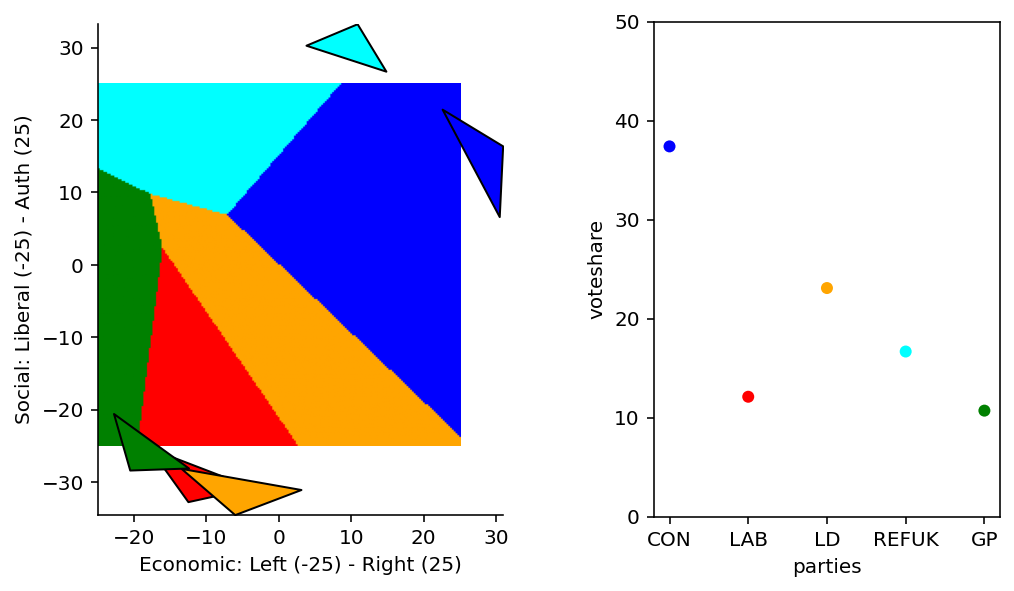

In [9]:
hv.extension('matplotlib')
import param
from panel.io import hold
angle_dict = OrderedDict()
valence_dict = OrderedDict()
steepness_dict = OrderedDict()
global family_missing_list

like_or_ptv_default = "ptv"
fw_wave_default = 30 #max_wave
range_dict = {"c3":(0.0,5.5),"angle":(-180,180),"steepness":(.5,4.5)}
# type_dict = {"c3":float,"angle":int}
party_list = ["CON","LAB","LD","REFUK","GP"] 
long_name_dict = { "CON":"Conservative","LAB":"Labour","LD":"Liberal Democrat","REFUK":"Reform UK/UKIP","GP":"Green",}

fw_wave_slider = pn.widgets.DiscreteSlider(  name = "Field Work Wave",
                                             value = fw_wave_default,
                                             options = [1987,1992,1997,2001,2005,2010,1,2,3,4,5, 2015,
                                                        6,7,8,9,10,11,12, 2017,
                                                        13,14,15,16,17,18, 2019,
                                                        19,
                                                        20,21,22,23,24,25,26,27,28, 2024,
                                                        29,30] )

# list(range(1,31))+[1997,2005,2010,2015,2017,2019]

# 1987,1992,2001, - don't have rad right parties

for param in ["angle","c3","steepness"]:
    family_missing_list = []
    for party in party_list:
        def_val = get_default_val(party,fw_wave_default,like_or_ptv_default,param)
        disabled=False
        if def_val is None:
            def_val = 1
            family_missing_list.append(party)
            disabled=True
                  
        if param=="angle":
            angle_dict[party.capitalize()+"_"+param] = pn.widgets.IntSlider(  name = long_name_dict[party]+" Party Position",
                                                                          value = def_val, disabled=disabled,
                                                                          start=range_dict[param][0],end=range_dict[param][1],)
        elif param=="c3":
            valence_dict[party.capitalize()+"_"+param] = pn.widgets.FloatSlider(name = long_name_dict[party]+" Party Valence",
                                                                          value = def_val, disabled=disabled,
                                                                          start=range_dict[param][0],end=range_dict[param][1])
        elif param=="steepness":
            steepness_dict[party.capitalize()+"_"+param] = pn.widgets.FloatSlider(name = long_name_dict[party]+" Party Polarisation",
                                                                          value = def_val, disabled=disabled,
                                                                          start=range_dict[param][0],end=range_dict[param][1])            


# ugly but works!
# refactor to have one setup function
def update_slider2(event):
    global family_missing_list

    angle_dict = OrderedDict()
    valence_dict = OrderedDict()
    steepness_dict = OrderedDict()
    for param in ["angle","c3","steepness"]:
        family_missing_list = []
        for party in party_list:
            def_val = get_default_val(party,fw_wave_slider.value,like_or_ptv_default,param)
            disabled=False
            if def_val is None:
                def_val = 1
                family_missing_list.append(party)
                disabled=True            
            if param=="angle":
                angle_dict[party.capitalize()+"_"+param] = pn.widgets.IntSlider(  name = long_name_dict[party]+" Party Position",
                                                                              value = def_val, disabled=disabled,
                                                                              start=range_dict[param][0],end=range_dict[param][1])
            elif param=="c3":
                valence_dict[party.capitalize()+"_"+param] = pn.widgets.FloatSlider(name = long_name_dict[party]+" Party Valence",
                                                                              value = def_val, disabled=disabled,
                                                                              start=range_dict[param][0],end=range_dict[param][1])
            elif param=="steepness":
                steepness_dict[party.capitalize()+"_"+param] = pn.widgets.FloatSlider(name = long_name_dict[party]+" Party Polarisation",
                                                                              value = def_val, disabled=disabled,
                                                                              start=range_dict[param][0],end=range_dict[param][1]) 
    # print(fw_wave_slider.param)
    app[3] = pn.Row( pn.Column( *angle_dict.values() ),
                        pn.Column( *valence_dict.values() ),
                        pn.Column( *steepness_dict.values() ), )
    dmap = hv.DynamicMap(
        
        pn.bind(get_int_pol_comp,
                Con_angle=angle_dict["Con_angle"],Lab_angle=angle_dict["Lab_angle"],Ld_angle=angle_dict["Ld_angle"],Refuk_angle=angle_dict["Refuk_angle"],Gp_angle=angle_dict["Gp_angle"],
                Con_c3=valence_dict["Con_c3"],Lab_c3=valence_dict["Lab_c3"],Ld_c3=valence_dict["Ld_c3"],Refuk_c3=valence_dict["Refuk_c3"],Gp_c3=valence_dict["Gp_c3"],            
                Con_steepness=steepness_dict["Con_steepness"],Lab_steepness=steepness_dict["Lab_steepness"],Ld_steepness=steepness_dict["Ld_steepness"],Refuk_steepness=steepness_dict["Refuk_steepness"],Gp_steepness=steepness_dict["Gp_steepness"],
                fw_wave = fw_wave_slider,
               
               ),
                        )
    app[0] = dmap
    # fw_wave_slider.selected=True
    

def cycle_through_waves(event):
    """
    Endless cycles through fieldwork waves
    """
    i = 0
    # options = ['world', 'you', 'there', 'human']
    while True:
        # yield f'Hello {options[i]}!'
        # fw_wave_slider.value = 1:30
        fw_wave_slider.value = (fw_wave_slider.value%max_wave) + 1
        print(fw_wave_slider.value)
        time.sleep(1)

    

pn.bind(update_slider2, fw_wave_slider, watch=True)
# pn.extension(throttled=True)
                
dmap = hv.DynamicMap(
    
    pn.bind(get_int_pol_comp,
            Con_angle=angle_dict["Con_angle"],Lab_angle=angle_dict["Lab_angle"],Ld_angle=angle_dict["Ld_angle"],Refuk_angle=angle_dict["Refuk_angle"],Gp_angle=angle_dict["Gp_angle"],
            Con_c3=valence_dict["Con_c3"],Lab_c3=valence_dict["Lab_c3"],Ld_c3=valence_dict["Ld_c3"],Refuk_c3=valence_dict["Refuk_c3"],Gp_c3=valence_dict["Gp_c3"],            
            Con_steepness=steepness_dict["Con_steepness"],Lab_steepness=steepness_dict["Lab_steepness"],Ld_steepness=steepness_dict["Ld_steepness"],Refuk_steepness=steepness_dict["Refuk_steepness"],Gp_steepness=steepness_dict["Gp_steepness"],
            fw_wave = fw_wave_slider,
           
           ),
                    )
checkbox = pn.widgets.Checkbox(name='Cycle Waves')
pn.bind(cycle_through_waves, checkbox, watch=True)


app = pn.Column( dmap, fw_wave_slider, checkbox,
                pn.Row( pn.Column( *angle_dict.values() ),
                        pn.Column( *valence_dict.values() ),
                        pn.Column( *steepness_dict.values() ), )).servable()
app

In [67]:
%debug

> c:\users\gamer\appdata\local\temp\ipykernel_29056\913128231.py(62)like_waves()



ipdb>  party_var


'GP'


ipdb>  family_missing_list


[]


ipdb>  quit


In [45]:
fw_wave_slider.param

Name,Value,Type,Range
align,'start',Align,
"<p style=""margin-bottom: 0px;"" class=""param-doc-tooltip"" data-tooltip=""Describes the proportional relationship between component's width and height. This works if any of component's dimensions are flexible in size. If set to a number, ``width / height = aspect_ratio`` relationship will be maintained. Otherwise, if set to ``""auto""``, component's preferred width and height will be used to determine the aspect (if not set, no aspect will be preserved)."">aspect_ratio",None,Aspect,nullable
bar_color,'#e6e6e6',Color,
css_classes,[],List,"(0, None)"
design,None,Selector,None
direction,'ltr',Selector,"'ltr', 'rtl'"
disabled,False,Boolean,
formatter,'%d',String,
height,None,Integer,nullable >=0
"<p style=""margin-bottom: 0px;"" class=""param-doc-tooltip"" data-tooltip=""Describes how the component should maintain its height. ``""auto""`` Use component's preferred sizing policy. ``""fixed""`` Use exactly ``height`` pixels. Component will overflow if it can't fit in the available vertical space. ``""fit""`` Use component's preferred height (if set) and allow to fit into the available vertical space within the minimum and maximum height bounds (if set). Component's height neither will be aggressively minimized nor maximized. ``""min""`` Use as little vertical space as possible, not less than the minimum height (if set). The starting point is the preferred height (if set). The height of the component may shrink or grow depending on the parent layout, aspect management and other factors. ``""max""`` Use as much vertical space as possible, not more than the maximum height (if set). The starting point is the preferred height (if set). The height of the component may shrink or grow depending on the parent layout, aspect management and other factors."">height_policy",'auto',Selector,"'auto', 'fixed', 'fit', 'min', 'max'"


:Layout
   .Overlay.I :Overlay
      .Image.I      :Image   [x,y]   (z)
      .Polygons.I   :Polygons   [x,y]
      .Polygons.II  :Polygons   [x,y]
      .Polygons.III :Polygons   [x,y]
      .Polygons.IV  :Polygons   [x,y]
      .Polygons.V   :Polygons   [x,y]
   .Bars.I    :Bars   [parties]   (voteshare,colour)
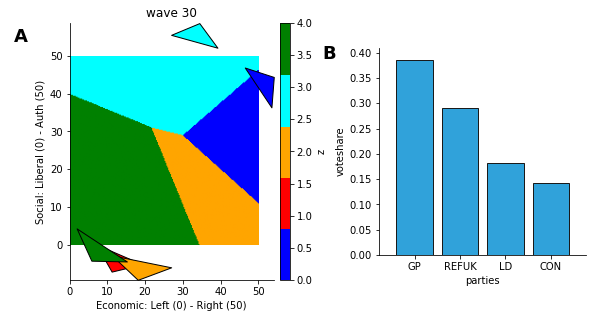

In [28]:
get_int_pol_comp(*[x.default for x in var_dict.values()])

In [65]:
# hv.extension('bokeh')
hv.help(hv.Points)

Points

Online example: https://holoviews.org/reference/elements/matplotlib/Points.html

-------------
Style Options
-------------

	alpha, c, cmap, color, ec, ecolor, edgecolor, edgecolors, facecolors, linewidth, lw, marker, norm, s, visible, vmax, vmin

(Consult matplotlib's documentation for more information.)

------------
Plot Options
------------

The plot options are the parameters of the plotting class:

Parameters of 'PointPlot'

Parameters changed from their default values are marked in red.
Soft bound values are marked in cyan.
C/V= Constant/Variable, RO/RW = ReadOnly/ReadWrite, AN=Allow None

Name                                   Value                    Type        Bounds     Mode  

fontsize                                None                 Parameter               V RW AN 
fontscale                               None                   Number                V RW AN 
show_title                              True                  Boolean                  V RW  
title      

In [196]:
hv.help(hv.Bars)

Bars

Online example: https://holoviews.org/reference/elements/matplotlib/Bars.html

-------------
Style Options
-------------

	align, alpha, c, capsize, color, ec, ecolor, edgecolor, error_kw, facecolor, fc, hatch, log, visible

(Consult matplotlib's documentation for more information.)

------------
Plot Options
------------

The plot options are the parameters of the plotting class:

Parameters of 'BarPlot'

Parameters changed from their default values are marked in red.
Soft bound values are marked in cyan.
C/V= Constant/Variable, RO/RW = ReadOnly/ReadWrite, AN=Allow None

Name                                   Value                    Type        Bounds     Mode  

fontsize                                None                 Parameter               V RW AN 
fontscale                               None                   Number                V RW AN 
show_title                              True                  Boolean                  V RW  
title                     '{label} {gr

In [8]:
import Panel as pn

ModuleNotFoundError: No module named 'Panel'

In [9]:
import Panel

ModuleNotFoundError: No module named 'Panel'

In [75]:
wave = 30
like_or_ptv = "like"
valence_replace_dict = None
angle_replace_dict = None
colors = ['blue','red', 'orange', 'cyan', 'green', ]
# color_dict = {0:'blue',1:'red',2:'orange',3:'cyan',4:'green', }
cmap = mpl.colors.ListedColormap(colors)
replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}    


like_numpy_orig = like_waves(wave,like_or_ptv,valence_replace_dict,angle_replace_dict)
if like_numpy_orig is not None:
    like_numpy = like_numpy_orig.replace(replace_dict).values.reshape((200, 200)).T[::-1]
    
    palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",}
    vote_share = like_numpy_orig.astype('category').cat.set_categories(replace_dict.keys()).value_counts(normalize=True).reset_index()   
    vote_share["colour"] = vote_share["index"].replace(palette_dict)
    vote_share.columns = ["parties","voteshare","colour"]          
    vote_share["voteshare"] = vote_share["voteshare"]*100
    



,parties,voteshare,colour
3,CON,14.3050,blue
4,LAB,0.0000,red
2,LD,18.2100,orange
1,REFUK,28.9625,cyan
0,GP,38.5225,green
